In [11]:
import datetime
import pandas as pd
import matplotlib.pyplot as plt
from utils import (
    get_historical_data,
    get_market_caps,
    calc_ceiling_performance,
    calc_floor_performance,
    get_sigma_aug,
    RunSimulatedAnnealing,
)

START_DATE = datetime.date(2023, 6, 29)
END_DATE = datetime.date(2026, 6, 29)

BENCHMARK = "SPY"  # Index we want to emulate
K = 20             # Number of securities we want to hold

TRADEABLE_STOCKS = list(pd.read_excel("S&P 500.xlsx")["Symbol"])

TRADEABLE_STOCKS = [s for s in TRADEABLE_STOCKS if s not in ["BF.B", "BRK.B"]]  # Reduced for compute niceness
N = len(TRADEABLE_STOCKS)



In [2]:
# Pull Data
historical_data = get_historical_data(TRADEABLE_STOCKS, START_DATE, END_DATE)
benchmark_data = get_historical_data(BENCHMARK, START_DATE, END_DATE)
market_caps = get_market_caps(TRADEABLE_STOCKS)

[*********************100%***********************]  501 of 501 completed
[*********************100%***********************]  1 of 1 completed


In [3]:
# Create covariance matrix
SIGMA = get_sigma_aug(historical_data, benchmark_data)

In [4]:
# calculate maximum performance
optimal_performance, _ = calc_ceiling_performance(SIGMA, N)
naive_performance = calc_floor_performance(market_caps, SIGMA, N)
    
print(f"Optimal performance TE: {optimal_performance:f}")
print(f"Naive performance TE: {naive_performance:f}")

Optimal performance TE: 0.000000
Naive performance TE: 0.000024


In [12]:
T_init = 8.6e-6
ALPHA = 0.999
N_STEPS = 4000

s, w, score, history = RunSimulatedAnnealing(
    N,
    SIGMA,
    n_steps=N_STEPS,
    T_init=T_init,
    alpha=ALPHA,
)

ValueError: not enough values to unpack (expected 4, got 3)

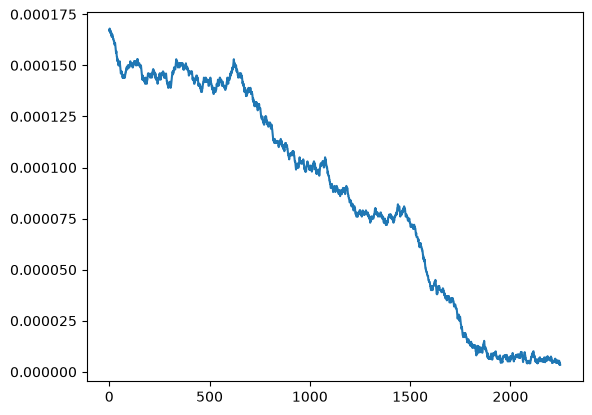

In [10]:
plt.plot(history["scoreHistory"])